In [1]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as stats
from scipy.stats import truncexpon
from scipy.stats import truncnorm
from scipy.stats import chi2
from scipy.stats import norm
import iminuit
from iminuit import Minuit
import matplotlib.pyplot as plt
from matplotlib import container
plt.rcParams["font.size"] = 14
print("iminuit version:", iminuit.__version__)  # need 2.x


iminuit version: 2.32.0


In [ ]:
np.random.seed(seed=1234567)        
theta = 0.2                         
mu = 10.                           
sigma = 2.                         
xi = 5.                            
xMin = 0.
xMax = 20.

def f(x, par):
    theta   = par[0]
    mu      = par[1]
    sigma   = par[2]
    xi      = par[3]
    fs = stats.truncnorm.pdf(x, a=(xMin-mu)/sigma, b=(xMax-mu)/sigma, loc=mu, scale=sigma)
    fb = stats.truncexpon.pdf(x, b=(xMax-xMin)/xi, loc=xMin, scale=xi)
    return theta*fs + (1-theta)*fb
        
numVal = 1000
xData = np.empty([numVal])
for i in range (numVal):
    r = np.random.uniform();
    if r < theta:
        xData[i] = stats.truncnorm.rvs(a=(xMin-mu)/sigma, b=(xMax-mu)/sigma, loc=mu, scale=sigma)
    else:
        xData[i] = stats.truncexpon.rvs(b=(xMax-xMin)/xi, loc=xMin, scale=xi)

In [3]:
def negLogL(par):
    pdf = f(xData, par)
    return -np.sum(np.log(pdf))

In [ ]:
parin   = np.array([theta, mu, sigma, xi]) 
parname = ['theta', 'mu', 'sigma', 'xi']
parname_latex = [r'$\theta$', r'$\mu$', r'$\sigma$', r'$\xi$']
parstep = np.array([0.1, 1., 1., 1.])      
parfix  = [False, True, True, False]       
parlim  = [(0.,1), (None, None), (0., None), (0., None)]    
m = Minuit(negLogL, parin, name=parname)
m.errors = parstep
m.fixed = parfix
m.limits = parlim
m.errordef = 0.5                          


In [5]:
trueVal = [theta, mu, sigma, xi]
result = np.array(f(np.linspace(xMin, xMax, 500), trueVal))

In [6]:
print(trueVal)

[0.2, 10.0, 2.0, 5.0]


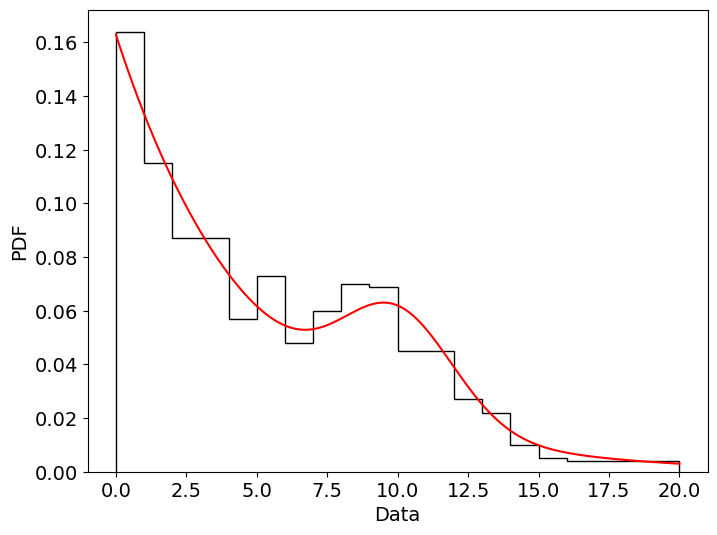

In [7]:
plt.figure(figsize=(8,6))
plt.hist(xData, bins=20, range=(xMin, xMax), density=True, histtype='step', color='black', label='data')
plt.plot(np.linspace(xMin, xMax, 500),result, color='red', label='true PDF')

plt.xlabel('Data')
plt.ylabel('PDF')
plt.show()

In [8]:
print(f(xData, trueVal))

[0.1617616  0.06223401 0.05868731 0.13659741 0.15785473 0.01851721
 0.05550027 0.06037514 0.13156152 0.10369149 0.07644912 0.05848543
 0.05347529 0.12762683 0.10811637 0.06304215 0.08819123 0.06855441
 0.08359174 0.10491071 0.10144705 0.07900373 0.06109352 0.06027335
 0.05387756 0.14874189 0.01390145 0.15202168 0.00415087 0.09713138
 0.05513387 0.05809496 0.06119684 0.07557392 0.1134761  0.13778755
 0.11996407 0.15505922 0.05554427 0.05559119 0.11294291 0.14540674
 0.03331472 0.00345338 0.04447856 0.10248315 0.11865201 0.096554
 0.05593748 0.13234626 0.06301076 0.05317107 0.1290559  0.15266807
 0.14665918 0.1587394  0.05646858 0.02188939 0.06180559 0.14320013
 0.054457   0.1401824  0.15947597 0.10620005 0.09347123 0.09544151
 0.05866    0.05296278 0.09946822 0.13845079 0.06173767 0.05922879
 0.06293157 0.02629317 0.0611029  0.06052546 0.06221306 0.05586913
 0.14744801 0.05983379 0.05579822 0.05410733 0.06932583 0.06288314
 0.04554043 0.05576191 0.07231819 0.06239322 0.07548919 0.029704

In [ ]:
m.migrad()                                        
MLE = m.values                                    
sigmaMLE = m.errors                               
cov = m.covariance                              
rho = m.covariance.correlation()                  
    
print(r"par index, name, estimate, standard deviation:")
for i in range(m.npar):
    if not m.fixed[i]:
        print("{:4d}".format(i), "{:<10s}".format(m.parameters[i]), " = ",
         "{:.6f}".format(MLE[i]), " +/- ", "{:.6f}".format(sigmaMLE[i]))

print()
print(r"free par indices, covariance, correlation coeff.:")
for i in range(m.npar):
    if not(m.fixed[i]):
        for j in range(m.npar):
            if not(m.fixed[j]):
                print(i, j, "{:.6f}".format(cov[i,j]), "{:.6f}".format(rho[i,j]))

par index, name, estimate, standard deviation:
   0 theta       =  0.209598  +/-  0.023271
   3 xi          =  4.736970  +/-  0.267242

free par indices, covariance, correlation coeff.:
0 0 0.000542 1.000000
0 3 -0.003415 -0.548807
3 0 -0.003415 -0.548807
3 3 0.071423 1.000000


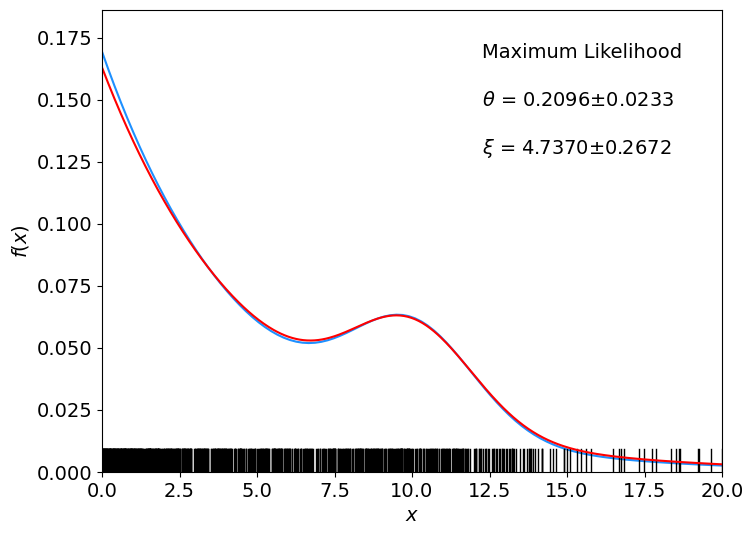

In [10]:
yMin = 0.
yMax = f(0., MLE)*1.1
fig = plt.figure(figsize=(8,6))
xCurve = np.linspace(xMin, xMax, 100)
yCurve = f(xCurve, MLE)
plt.plot(xCurve, yCurve, color='dodgerblue')
plt.xlabel(r'$x$')
plt.ylabel(r'$f(x)$')
y_fitval = 0.8
delta_y_fitval = 0.08
plt.figtext(0.6, y_fitval, 'Maximum Likelihood')
for i in range(len(parin)):
    if not parfix[i]:
        y_fitval -= delta_y_fitval
        plt.figtext(0.6, y_fitval, parname_latex[i] + ' = ' + f'{MLE[i]:.4f}' + r'$\pm$' + f'{sigmaMLE[i]:.4f}')
        

tick_height = 0.05*(yMax - yMin)
xvals = [xData, xData]
yvals = [np.zeros_like(xData), tick_height * np.ones_like(xData)]
plt.plot(xvals, yvals, color='black', linewidth=1)
plt.plot(np.linspace(xMin, xMax, 500),result, color='red', label='true PDF')
plt.xlim(xMin, xMax)
plt.ylim(yMin, yMax)
plt.show()

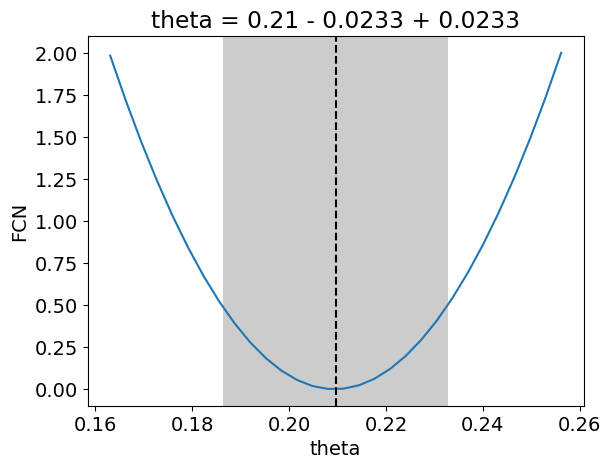

In [11]:
if not(m.fixed['theta']):
    plt.figure()
    m.draw_mnprofile('theta')
    plt.show()


CL =  0.3934693402873665


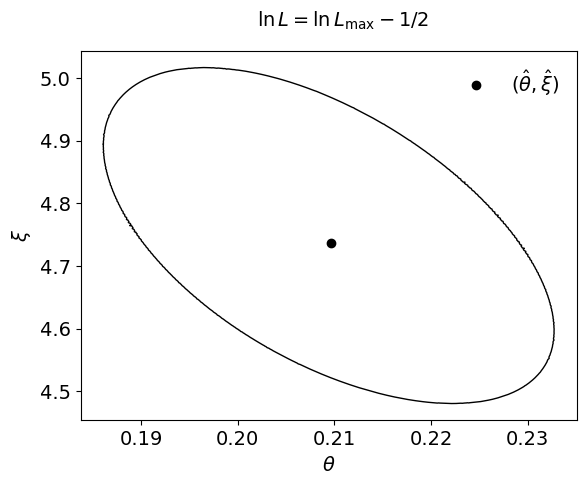

In [ ]:
CL = stats.chi2.cdf(1.,2)            
print('CL = ', CL)
if not(m.fixed['theta'] | m.fixed['xi']):
    fig, ax = plt.subplots(1,1)
    con = m.mncontour('theta', 'xi', cl=CL, size=1000)
    con = np.vstack([con, con[0]])         # close contour
    
    plt.plot(MLE[0], MLE[3], marker='o', linestyle='None', color='black', label=r'$(\hat{\theta}, \hat{\xi})$')
    plt.plot(con[:,0], con[:,1], color='black', linewidth=1)
    plt.xlabel(r'$\theta$', labelpad=5)
    plt.ylabel(r'$\xi$', labelpad=5)
    handles, labels = ax.get_legend_handles_labels()
    plt.legend(handles, labels, loc='upper right', fontsize=14, frameon=False)
    plt.figtext(0.4, 0.93, r'$\ln L = \ln L_{\rm max} - 1/2$')
    plt.show()


CL =  0.3934693402873665


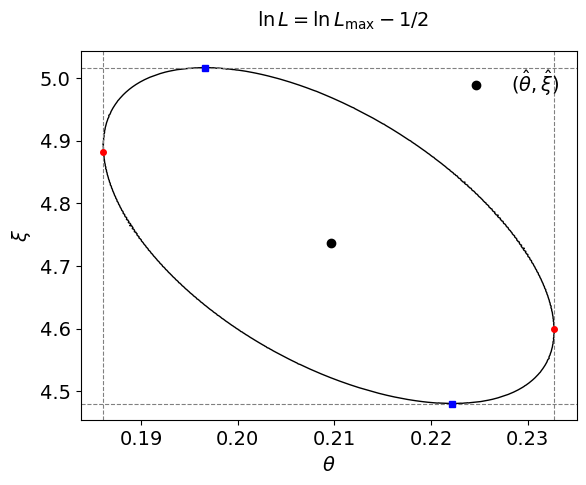

In [ ]:
CL = stats.chi2.cdf(1., 2)
print('CL = ', CL)
if not (m.fixed['theta'] | m.fixed['xi']):
    fig, ax = plt.subplots(1, 1)
    con = m.mncontour('theta', 'xi', cl=CL, size=1000)
    con = np.vstack([con, con[0]])         

 
    i_xmin, i_xmax = np.argmin(con[:, 0]), np.argmax(con[:, 0])
    i_ymin, i_ymax = np.argmin(con[:, 1]), np.argmax(con[:, 1])
    xmin, xmax = con[i_xmin, 0], con[i_xmax, 0]
    ymin, ymax = con[i_ymin, 1], con[i_ymax, 1]

    plt.plot(MLE[0], MLE[3], marker='o', linestyle='None', color='black',
             label=r'$(\hat{\theta}, \hat{\xi})$')
    plt.plot(con[:, 0], con[:, 1], color='black', linewidth=1)

   
    for x in (xmin, xmax):
        ax.axvline(x, color='gray', linestyle='--', linewidth=0.8)   
    for y in (ymin, ymax):
        ax.axhline(y, color='gray', linestyle='--', linewidth=0.8)   

    
    ax.plot(con[[i_xmin, i_xmax], 0], con[[i_xmin, i_xmax], 1], 'o', color='red', ms=4)
    ax.plot(con[[i_ymin, i_ymax], 0], con[[i_ymin, i_ymax], 1], 's', color='blue', ms=4)

    plt.xlabel(r'$\theta$', labelpad=5)
    plt.ylabel(r'$\xi$', labelpad=5)
    handles, labels = ax.get_legend_handles_labels()
    plt.legend(handles, labels, loc='upper right', fontsize=14, frameon=False)
    plt.figtext(0.4, 0.93, r'$\ln L = \ln L_{\rm max} - 1/2$')
    plt.show()

In [14]:
print('theta range:', xmin, xmax)
print('xi range:   ', ymin, ymax)

theta range: 0.1860748423868277 0.2327213628468043
xi range:    4.48029407785736 5.01661129824424


CL =  0.3934693402873665


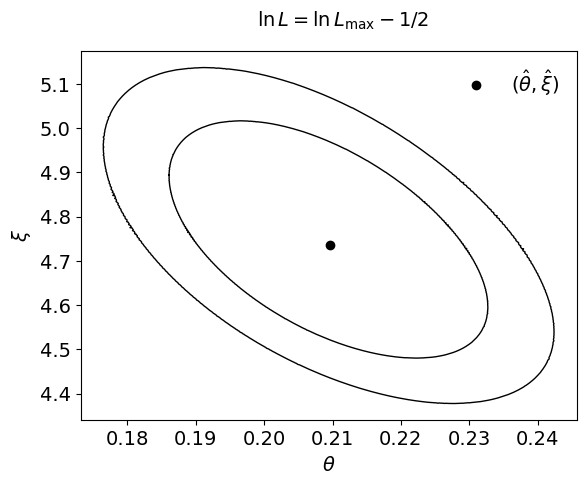

In [15]:
CL = stats.chi2.cdf(1, 2)
CL2 = stats.chi2.cdf(2, 2)
print('CL = ', CL)
if not (m.fixed['theta'] | m.fixed['xi']):
    fig, ax = plt.subplots(1, 1)
    con1 = m.mncontour('theta', 'xi', cl=CL, size=1000)
    con1 = np.vstack([con1, con1[0]])         # close contour
    con2 = m.mncontour('theta', 'xi', cl=CL2, size=1000)
    con2 = np.vstack([con2, con2[0]])         # close contour

 
    i_xmin, i_xmax = np.argmin(con1[:, 0]), np.argmax(con1[:, 0])
    i_ymin, i_ymax = np.argmin(con1[:, 1]), np.argmax(con1[:, 1])
    xmin, xmax = con1[i_xmin, 0], con1[i_xmax, 0]
    ymin, ymax = con1[i_ymin, 1], con1[i_ymax, 1]

    plt.plot(MLE[0], MLE[3], marker='o', linestyle='None', color='black',
             label=r'$(\hat{\theta}, \hat{\xi})$')
    plt.plot(con1[:, 0], con1[:, 1], color='black', linewidth=1)
    plt.plot(con2[:, 0], con2[:, 1], color='black', linewidth=1)

   

    plt.xlabel(r'$\theta$', labelpad=5)
    plt.ylabel(r'$\xi$', labelpad=5)
    handles, labels = ax.get_legend_handles_labels()
    plt.legend(handles, labels, loc='upper right', fontsize=14, frameon=False)
    plt.figtext(0.4, 0.93, r'$\ln L = \ln L_{\rm max} - 1/2$')
    plt.show()

In [16]:
con1.shape

(1002, 2)

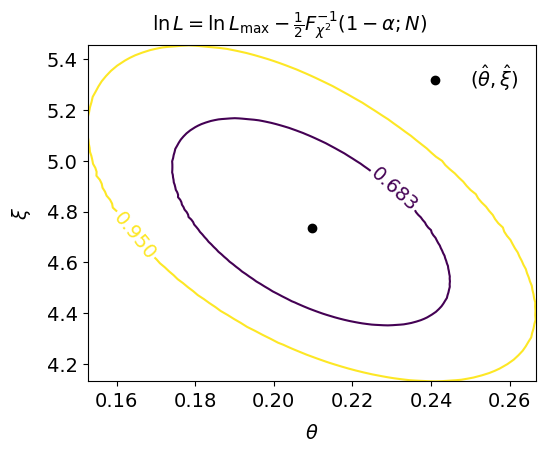

In [17]:
if not(m.fixed['theta'] | m.fixed['xi']):
    fig, ax = plt.subplots(1,1)
    m.draw_mncontour('theta', 'xi', cl=[0.683, 0.95], size=200);
    plt.plot(MLE[0], MLE[3], marker='o', linestyle='None', color='black', label=r'$(\hat{\theta}, \hat{\xi})$')
    plt.xlabel(r'$\theta$', labelpad=10)
    plt.ylabel(r'$\xi$', labelpad=10)
    plt.subplots_adjust(left=0.2, right=0.9, top=0.9, bottom=0.2)
    handles, labels = ax.get_legend_handles_labels()
    plt.legend(handles, labels, loc='upper right', fontsize=14, frameon=False)
    plt.figtext(0.3, 0.93, r'$\ln L = \ln L_{\rm max} - \frac{1}{2} F^{-1}_{\chi^2}(1-\alpha;N)$')
    plt.show()

 



In [ ]:
np.random.seed(seed=1234567)       
theta = 0.2                         
mu = 10.                       
sigma = 2.                          
xi = 5.                          
xMin = 0.
xMax = 20.

def f(x, par):
    theta   = par[0]
    mu      = par[1]
    sigma   = par[2]
    xi      = par[3]
    fs = stats.truncnorm.pdf(x, a=(xMin-mu)/sigma, b=(xMax-mu)/sigma, loc=mu, scale=sigma)
    fb = stats.truncexpon.pdf(x, b=(xMax-xMin)/xi, loc=xMin, scale=xi)
    return theta*fs + (1-theta)*fb

numVal = np.array([100, 200, 400, 800])
for i in range(len(numVal)):
    xData = np.empty(numVal[i])
    for j in range(numVal[i]):
        r = np.random.uniform()
        if r < theta:
            xData[j] = stats.truncnorm.rvs(a=(xMin-mu)/sigma, b=(xMax-mu)/sigma, loc=mu, scale=sigma)
        else:
            xData[j] = stats.truncexpon.rvs(b=(xMax-xMin)/xi, loc=xMin, scale=xi)

    parin = np.array([theta, mu, sigma, xi])  
    parname = ['theta', 'mu', 'sigma', 'xi']
    parname_latex = [r'$\theta$', r'$\mu$', r'$\sigma$', r'$\xi$']
    parstep = np.array([0.1, 1., 1., 1.])     
    parfix = [False, True, True, False]        
    parlim = [(0., 1), (None, None), (0., None), (0., None)] 
    m = Minuit(negLogL, parin, name=parname)
    m.errors = parstep
    m.fixed = parfix
    m.limits = parlim
    m.errordef = 0.5  

    m.migrad()  # minimize -logL
    MLE = m.values
    sigmaMLE = m.errors
    cov = m.covariance
    rho = m.covariance.correlation()

    print(r"par index, name, estimate, standard deviation:")
    for k in range(4):
        if not m.fixed[k]:
           
           print(f"{k:4d}      {m.parameters[k]:<10s} =     {MLE[k]:.6f} +/- {sigmaMLE[k]:.6f} for {numVal[i]} data points")

par index, name, estimate, standard deviation:
   0      theta      =     0.197218 +/- 0.071219 for 100 data points
   3      xi         =     4.432462 +/- 0.778480 for 100 data points
par index, name, estimate, standard deviation:
   0      theta      =     0.129997 +/- 0.052451 for 200 data points
   3      xi         =     5.956525 +/- 0.733312 for 200 data points
par index, name, estimate, standard deviation:
   0      theta      =     0.206662 +/- 0.036147 for 400 data points
   3      xi         =     4.360020 +/- 0.391726 for 400 data points
par index, name, estimate, standard deviation:
   0      theta      =     0.230561 +/- 0.026067 for 800 data points
   3      xi         =     4.877187 +/- 0.311808 for 800 data points


In [19]:
np.random.seed(seed=1234567)
theta = 0.2
mu = 10.
sigma = 2.
xi = 5.
xMin = 0.
xMax = 20.

numVal = 1000
xData = np.empty([numVal])
for i in range(numVal):
    r = np.random.uniform()
    if r < theta:
        xData[i] = stats.truncnorm.rvs(a=(xMin-mu)/sigma, b=(xMax-mu)/sigma, loc=mu, scale=sigma)
    else:
        xData[i] = stats.truncexpon.rvs(b=(xMax-xMin)/xi, loc=xMin, scale=xi)

parin = np.array([theta, mu, sigma, xi])
parname = ['theta', 'mu', 'sigma', 'xi']
parstep = np.array([0.1, 1., 1., 1.])
parlim = [(0., 1), (None, None), (0., None), (0., None)]

cases = [[False, True, True, True],
         [False, True, True, False],
         [False, True, False, False],
         [False, False, False, False]]

for parfix in cases:
    m = Minuit(negLogL, parin, name=parname)
    m.errors = parstep
    m.fixed = parfix
    m.limits = parlim
    m.errordef = 0.5
    m.migrad()
    print(parfix, "theta_hat = {:.4f} +/- {:.4f}".format(m.values['theta'], m.errors['theta']))

[False, True, True, True] theta_hat = 0.1973 +/- 0.0196
[False, True, True, False] theta_hat = 0.2096 +/- 0.0233
[False, True, False, False] theta_hat = 0.2099 +/- 0.0284
[False, False, False, False] theta_hat = 0.2312 +/- 0.0344


In [ ]:
np.random.seed(seed=1234567)        
theta = 0.2                         
mu = 10.                           
sigma = 2.                         
xi = 5.                             
xMin = 0.
xMax = 20.

def f(x, par):
    theta   = par[0]
    mu      = par[1]
    sigma   = par[2]
    xi      = par[3]
    fs = stats.truncnorm.pdf(x, a=(xMin-mu)/sigma, b=(xMax-mu)/sigma, loc=mu, scale=sigma)
    fb = stats.truncexpon.pdf(x, b=(xMax-xMin)/xi, loc=xMin, scale=xi)
    return theta*fs + (1-theta)*fb

numVal = 200
xData = np.empty(numVal)
for i in range(numVal):
    r = np.random.uniform()
    if r < theta:
        xData[i] = stats.truncnorm.rvs(a=(xMin-mu)/sigma, b=(xMax-mu)/sigma, loc=mu, scale=sigma)
    else:
        xData[i] = stats.truncexpon.rvs(b=(xMax-xMin)/xi, loc=xMin, scale=xi)



In [24]:
xi_mean = 5.0
xi_sigma = 0.5

def negLogPosterior(par):
    theta   = par[0]
    mu      = par[1]
    sigma   = par[2]
    xi      = par[3]
    if xi <= 0 or sigma <= 0 or theta < 0 or theta > 1:
        return np.inf

    pdf = f(xData, par)
    pdf = np.clip(pdf, 1e-300, None)

    logL = -np.sum(np.log(pdf))
    prior = 0.5 * ((xi - xi_mean) / xi_sigma) ** 2
    return  (logL + prior)

In [ ]:
parin = np.array([theta, mu, sigma, xi])  
parname = ['theta', 'mu', 'sigma', 'xi']
parname_latex = [r'$\theta$', r'$\mu$', r'$\sigma$', r'$\xi$']
parstep = np.array([0.1, 1., 1., 1.])     
parfix = [False, True, True, False]      
parlim = [(0., 1), (None, None), (0, None), (0., None)] 
m = Minuit(negLogPosterior, parin, name=parname)
m.errors = parstep
m.fixed = parfix
m.limits = parlim
m.errordef = 0.5  

In [ ]:
m.migrad()  
MLE = m.values
sigmaMLE = m.errors
cov = m.covariance
rho = m.covariance.correlation()

print(r"par index, name, estimate, standard deviation:")
for k in range(4):
    if not m.fixed[k]:
        print(f"{k:4d}      {m.parameters[k]:<10s} =     {MLE[k]:.6f} +/- {sigmaMLE[k]:.6f}")

print("With gaussian prior on xi: mean = {:.2f}, sigma = {:.2f}".format(xi_mean, xi_sigma))

par index, name, estimate, standard deviation:
   0      theta      =     0.207529 +/- 0.047699
   3      xi         =     5.041264 +/- 0.392221
With gaussian prior on xi: mean = 5.00, sigma = 0.50
